<a href="https://colab.research.google.com/github/ayeshaazahidd0-stack/Digital-Image-Processing/blob/main/DIP_Lab3_Ayesha_Zahis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

LAB 3 — HSV Masking & Intensity Transforms (Negative, Log, Gamma)



In [ ]:
import cv2, numpy as np
from google.colab.patches import cv2_imshow
from google.colab import files
import matplotlib.pyplot as plt


Task 1 — Blue Object Isolation on a Desk (HSV Mask)

Please upload your workspace photo:


Saving workplaceimage.jpeg to workplaceimage.jpeg

--- Original Image ---


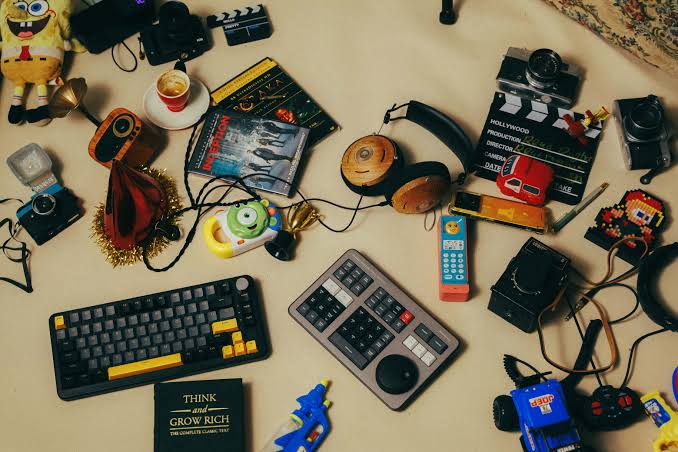


--- Binary Mask (Blue Range) ---


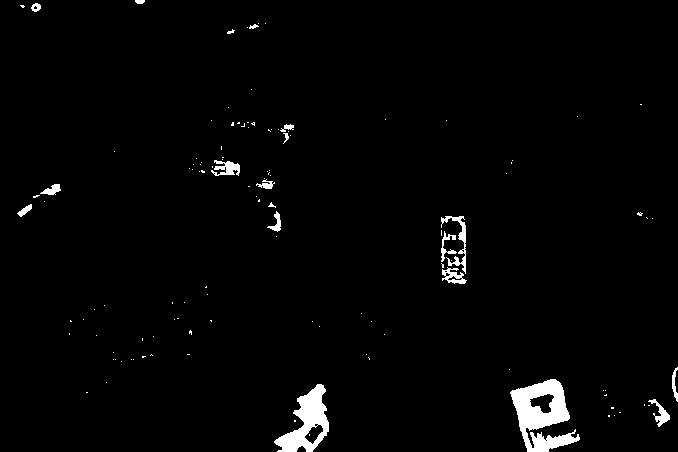


--- Extracted Blue Objects ---


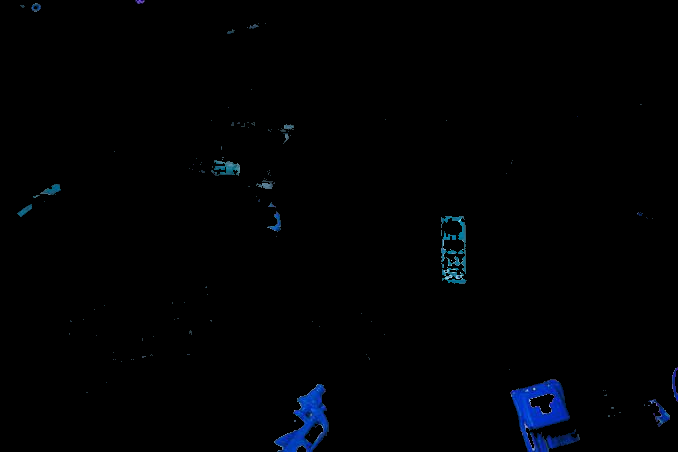


Final H, S, V Ranges:
Lower Blue Limit (H, S, V): [95, 80, 60]
Upper Blue Limit (H, S, V): [130, 255, 255]


In [ ]:
from google.colab import files
import cv2
import numpy as np
from google.colab.patches import cv2_imshow

# Step 1: Upload the workspace image
print("Please upload your workspace photo:")
uploaded = files.upload()
if len(uploaded) > 0:
    # Get the first uploaded file name
    img_name = list(uploaded.keys())[0]
    img_mask_bgr = cv2.imread(img_name)

    # Step 2: Convert BGR to HSV
    hsvA = cv2.cvtColor(img_mask_bgr, cv2.COLOR_BGR2HSV)

    # Step 3: Define range of blue color in HSV
    # H range: [95, 130], S range: [80, 255], V range: [60, 255]
    lower_blue = np.array([95, 80, 60])
    upper_blue = np.array([130, 255, 255])

    # Step 4: Threshold the HSV image to get only blue colors
    mask = cv2.inRange(hsvA, lower_blue, upper_blue)

    # Step 5: Bitwise-AND mask and original image to extract blue objects
    blue_isolated = cv2.bitwise_and(img_mask_bgr, img_mask_bgr, mask=mask)

    # Step 6: Display results
    print("\n--- Original Image ---")
    cv2_imshow(img_mask_bgr)

    print("\n--- Binary Mask (Blue Range) ---")
    cv2_imshow(mask)

    print("\n--- Extracted Blue Objects ---")
    cv2_imshow(blue_isolated)

    # Print ranges
    print(f"\nFinal H, S, V Ranges:")
    print(f"Lower Blue Limit (H, S, V): {lower_blue.tolist()}")
    print(f"Upper Blue Limit (H, S, V): {upper_blue.tolist()}")
else:
    print("No file uploaded. Please run the cell again to upload an image.")

Task 2 — Magenta Branding Emphasis (Keep-Only)

Please upload your packaging image with magenta accents:


Saving packaginng photo.jpg to packaginng photo.jpg

--- Original Packaging Image ---


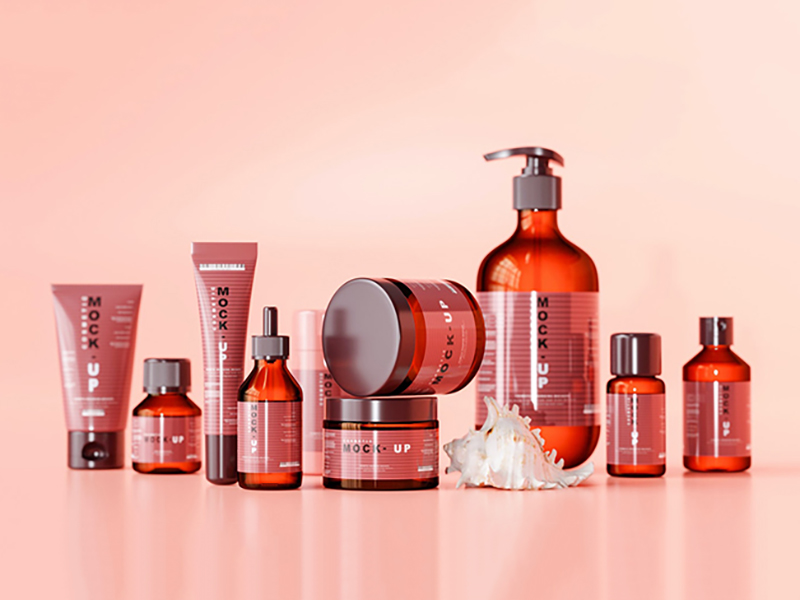


--- Isolated Magenta Accents ---


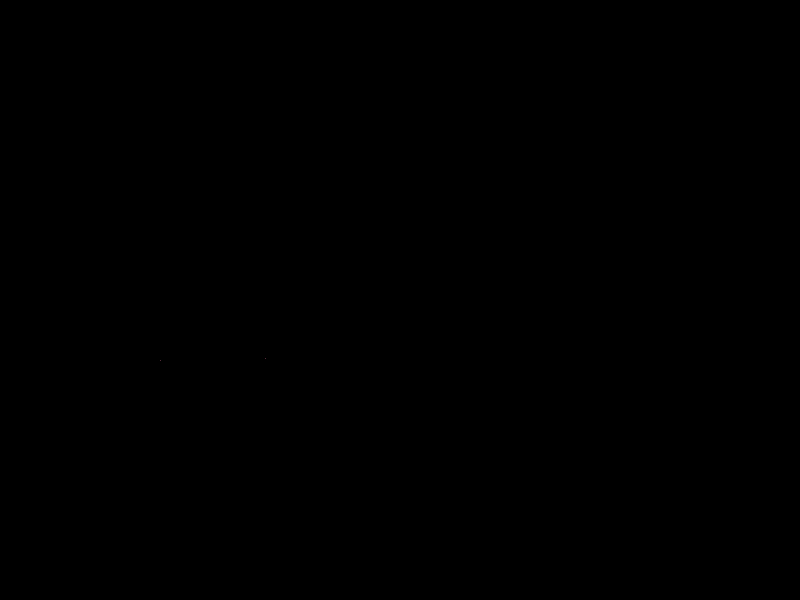


* To avoid false positives (e.g. from background shadows or similar warm-colored artifacts), tighten the saturation (S) and brightness (V) minimum thresholds.*


In [ ]:
# Step 1: Upload the packaging image
print("Please upload your packaging image with magenta accents:")
upload_magenta = files.upload()
if len(upload_magenta) > 0:
    # Get the uploaded file name
    img_name_m = list(upload_magenta.keys())[0]
    img_magenta_bgr = cv2.imread(img_name_m)

    # Step 2: Convert BGR to HSV
    hsv_m = cv2.cvtColor(img_magenta_bgr, cv2.COLOR_BGR2HSV)

    # Step 3: Define range of magenta in HSV
    # H: [145, 170], S: [100, 255], V: [80, 255]
    lower_magenta = np.array([145, 100, 80])
    upper_magenta = np.array([170, 255, 255])

    # Step 4: Create mask and apply bitwise AND
    mask_magenta = cv2.inRange(hsv_m, lower_magenta, upper_magenta)
    magenta_isolated = cv2.bitwise_and(img_magenta_bgr, img_magenta_bgr, mask=mask_magenta)

    # Step 5: Display original vs isolated result
    print("\n--- Original Packaging Image ---")
    cv2_imshow(img_magenta_bgr)

    print("\n--- Isolated Magenta Accents ---")
    cv2_imshow(magenta_isolated)

    # Step 6: Note on avoiding false positives
    print("\n* To avoid false positives (e.g. from background shadows or similar warm-colored artifacts), tighten the saturation (S) and brightness (V) minimum thresholds.*")
else:
    print("No file uploaded. Please run the cell again to upload an image.")

Task 3 — Green Foliage Suppression (Mask Inversion)

Please upload your street-architecture image with green foliage:


Saving streetarchitecturestudy.jpeg to streetarchitecturestudy.jpeg

--- Original Image ---


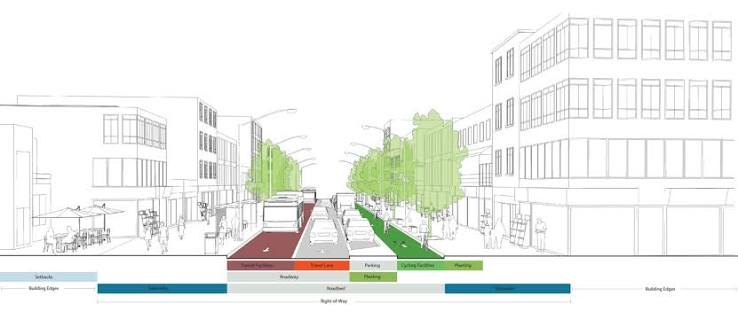


--- Green Mask (Foliage Detected) ---


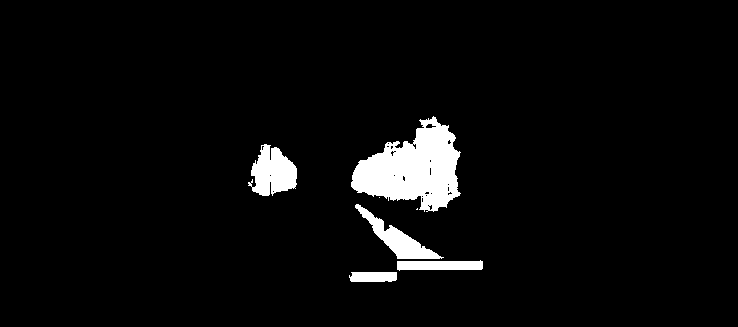


--- Foliage Suppressed Result (Inverted-Mask Applied) ---


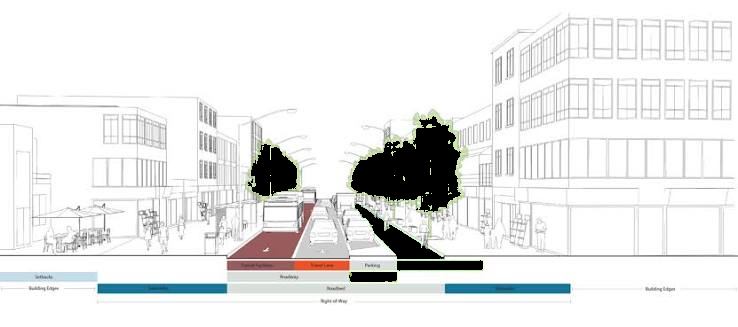


* Note on Mask Inversion:
In a standard mask, white pixels (255) designate the target color (green) that we want to keep, while black pixels (0) represent everything else. By inverting the mask using bitwise_not, we flip this logic: green elements become black (0) and are suppressed, while everything else becomes white (255) and is preserved in the bitwise_and operation.


In [ ]:
# Step 1: Upload the architecture image
print("Please upload your street-architecture image with green foliage:")
upload_green = files.upload()
if len(upload_green) > 0:
    # Get the uploaded file name
    img_name_g = list(upload_green.keys())[0]
    img_arch_bgr = cv2.imread(img_name_g)

    # Step 2: Convert BGR to HSV
    hsv_g = cv2.cvtColor(img_arch_bgr, cv2.COLOR_BGR2HSV)

    # Step 3: Define range of green in HSV
    # H: [40, 75], S: [60, 255], V: [50, 255]
    lower_green = np.array([40, 60, 50])
    upper_green = np.array([75, 255, 255])

    # Step 4: Create the green mask
    mask_green = cv2.inRange(hsv_g, lower_green, upper_green)

    # Step 5: Invert the mask
    # This turns green areas (white in mask) to black (0) and non-green areas to white (255)
    mask_inverted = cv2.bitwise_not(mask_green)

    # Step 6: Apply the inverted mask to black out the green regions
    foliage_suppressed = cv2.bitwise_and(img_arch_bgr, img_arch_bgr, mask=mask_inverted)

    # Step 7: Display results
    print("\n--- Original Image ---")
    cv2_imshow(img_arch_bgr)

    print("\n--- Green Mask (Foliage Detected) ---")
    cv2_imshow(mask_green)

    print("\n--- Foliage Suppressed Result (Inverted-Mask Applied) ---")
    cv2_imshow(foliage_suppressed)

    # Explanation of inversion
    print("\n* Note on Mask Inversion:")
    print("In a standard mask, white pixels (255) designate the target color (green) that we want to keep, while black pixels (0) represent everything else. By inverting the mask using bitwise_not, we flip this logic: green elements become black (0) and are suppressed, while everything else becomes white (255) and is preserved in the bitwise_and operation.")
else:
    print("No file uploaded. Please run the cell again to upload an image.")

Task 4 — Dim Journal Page: Log Transform

In [ ]:
from google.colab import files
import cv2
import numpy as np
from google.colab.patches import cv2_imshow
from PIL import Image
import io

# Step 1: Upload the dim journal page image
print("Please upload your dim journal page image:")
upload_journal = files.upload()
if len(upload_journal) > 0:
    # Get the uploaded file name
    img_name_j = list(upload_journal.keys())[0]

    # Use PIL to read the image to robustly support .avif formats
    file_bytes = upload_journal[img_name_j]
    pil_img = Image.open(io.BytesIO(file_bytes))
    img_journal_bgr = cv2.cvtColor(np.array(pil_img), cv2.COLOR_RGB2BGR)

    # Step 2: Convert to grayscale
    gray = cv2.cvtColor(img_journal_bgr, cv2.COLOR_BGR2GRAY)

    # Step 3: Scale to [0,1] range
    gray_normalized = gray.astype(np.float32) / 255.0

    # Step 4: Apply log transform (using log1p which is log(1 + x))
    c = 1.0 / np.log(1.0 + 1.0)
    log_transformed = c * np.log1p(gray_normalized)

    # Step 5: Rescale back to uint8 [0, 255]
    log_transformed_uint8 = np.clip(log_transformed * 255.0, 0, 255).astype(np.uint8)

    # Step 6: Show side-by-side with original grayscale
    comparison = np.hstack((gray, log_transformed_uint8))
    print("\n--- Side-by-Side Comparison (Original Grayscale vs Log Transformed) ---")
    cv2_imshow(comparison)

    # Step 7: Print sample pixel values before and after to show non-linear boost
    h, w = gray.shape
    mid_y, mid_x = h // 2, w // 2
    val_before = gray[mid_y, mid_x]
    val_after = log_transformed_uint8[mid_y, mid_x]

    print(f"\n--- Non-linear Boost Demonstration ---")
    print(f"Pixel location: ({mid_x}, {mid_y})")
    print(f"Intensity Before Log Transform: {val_before} / 255")
    print(f"Intensity After Log Transform:  {val_after} / 255")
    print("This shows how dark pixels are lifted significantly without oversaturating/blowing out the highlights.")
else:
    print("No file uploaded. Please run the cell again to upload an image.")

Task 5 — Indoor Night Scene: Gamma Sweep

Please upload your indoor night scene image:


Saving cafe.jpeg to cafe.jpeg

--- Gamma Sweep Comparison (gamma = 0.65 | gamma = 1.0 | gamma = 1.8) ---


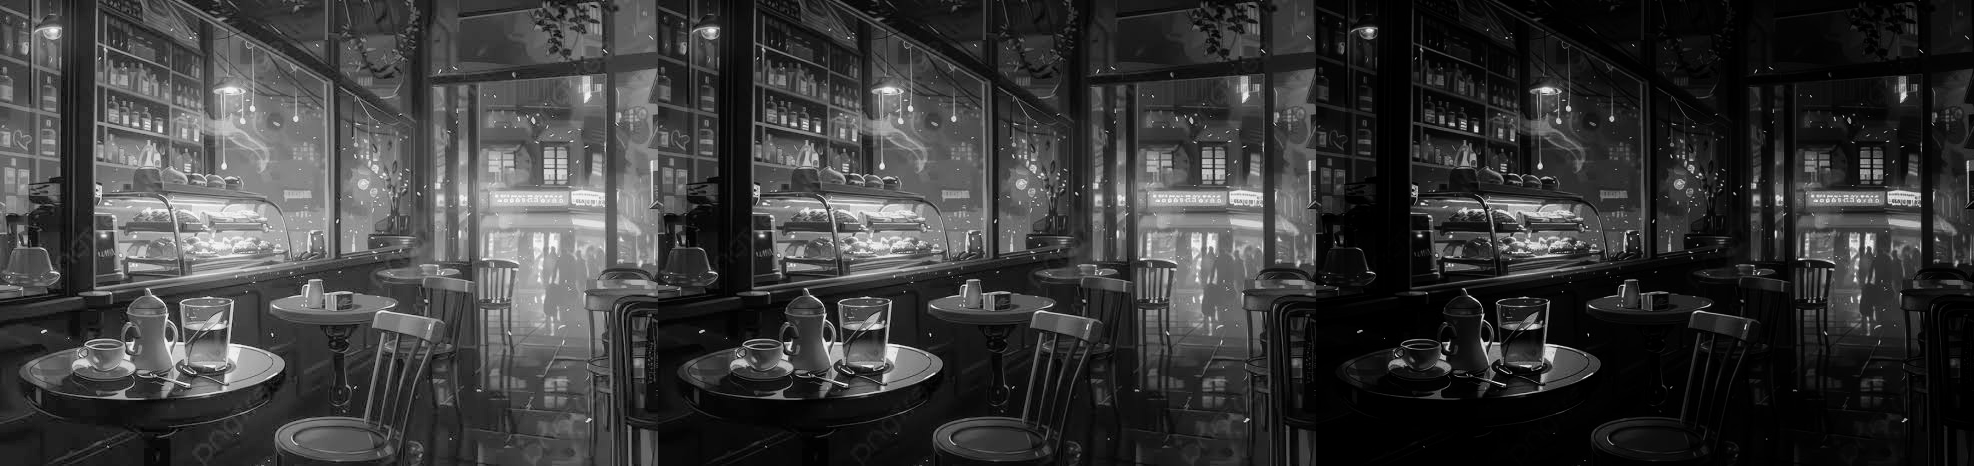


* Print Recommendation & Rationale:
We recommend gamma = 0.65 for the print poster. This value lifts the dark midtones and shadow details in the night shot, making the scene feel warm and cozy, without blowing out the highlights as a linear stretch or a steeper curve might.


In [ ]:
from google.colab import files
import cv2
import numpy as np
from google.colab.patches import cv2_imshow
from PIL import Image
import io

# Step 1: Upload the indoor night scene image
print("Please upload your indoor night scene image:")
upload_night = files.upload()
if len(upload_night) > 0:
    # Get the uploaded file name
    img_name_n = list(upload_night.keys())[0]

    # Use PIL to read the image safely
    file_bytes = upload_night[img_name_n]
    pil_img = Image.open(io.BytesIO(file_bytes))
    img_night_bgr = cv2.cvtColor(np.array(pil_img), cv2.COLOR_RGB2BGR)

    # Step 2: Convert to grayscale
    gray_night = cv2.cvtColor(img_night_bgr, cv2.COLOR_BGR2GRAY)

    # Step 3: Scale to [0, 1] for power law (gamma) transformation
    gray_normalized = gray_night.astype(np.float32) / 255.0

    # Step 4: Perform gamma correction for gamma = 0.65, 1.0, 1.8
    # Gamma correction formula: O = I^gamma
    gamma_065 = np.power(gray_normalized, 0.65)
    gamma_100 = np.power(gray_normalized, 1.0)
    gamma_180 = np.power(gray_normalized, 1.8)

    # Step 5: Rescale back to uint8 [0, 255]
    out_065 = np.clip(gamma_065 * 255.0, 0, 255).astype(np.uint8)
    out_100 = np.clip(gamma_100 * 255.0, 0, 255).astype(np.uint8)
    out_180 = np.clip(gamma_180 * 255.0, 0, 255).astype(np.uint8)

    # Step 6: Create a 3-tile panel side-by-side (hstack)
    panel = np.hstack((out_065, out_100, out_180))
    print("\n--- Gamma Sweep Comparison (gamma = 0.65 | gamma = 1.0 | gamma = 1.8) ---")
    cv2_imshow(panel)

    # Step 7: Justification/Rationale
    print("\n* Print Recommendation & Rationale:")
    print("We recommend gamma = 0.65 for the print poster. This value lifts the dark midtones and shadow details in the night shot, making the scene feel warm and cozy, without blowing out the highlights as a linear stretch or a steeper curve might.")
else:
    print("No file uploaded. Please run the cell again to upload an image.")

Task 6 — Print-Friendly Blueprint (Image Negative)

Please upload your blueprint image:


Saving old print.jpeg to old print (1).jpeg

--- Side-by-Side Comparison (Grayscale vs Inverted Negative) ---


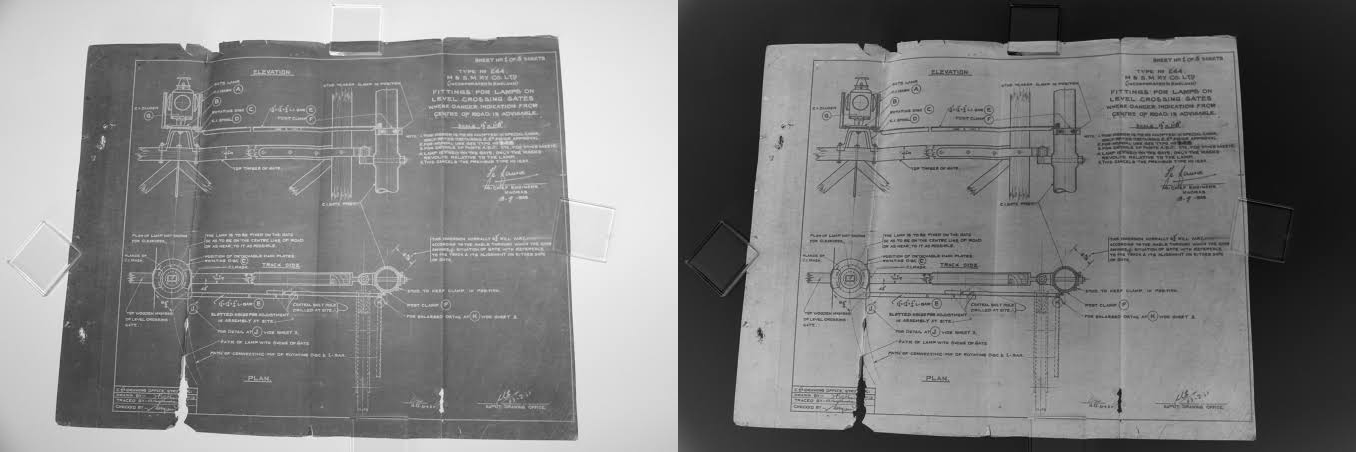


--- Pixel Inversion Report ---
Background (typically dark in original) at (169, 113): 106 ---> 149
Drawing Line (typically bright in original) at (339, 226): 132 ---> 123
Text/Annotation (typically bright in original) at (508, 339): 115 ---> 140

* Why Inversion Helps:
Converting light-on-dark blueprints to dark-on-light negatives saves a substantial amount of printer ink/toner. Additionally, dark markings on a light background align with human reading habits, making details and annotated text far more legible and easier to mark up on paper.


In [ ]:
from google.colab import files
import cv2
import numpy as np
from google.colab.patches import cv2_imshow
from PIL import Image
import io

# Step 1: Upload the blueprint image
print("Please upload your blueprint image:")
upload_blueprint = files.upload()
if len(upload_blueprint) > 0:
    # Get the uploaded file name
    img_name_b = list(upload_blueprint.keys())[0]

    # Use PIL to read the image to support various image formats safely
    file_bytes = upload_blueprint[img_name_b]
    pil_img = Image.open(io.BytesIO(file_bytes))
    img_blueprint_bgr = cv2.cvtColor(np.array(pil_img), cv2.COLOR_RGB2BGR)

    # Step 2: Convert to grayscale
    gray_blueprint = cv2.cvtColor(img_blueprint_bgr, cv2.COLOR_BGR2GRAY)

    # Step 3: Compute the negative (255 - I_gray) using safe uint8 math
    negative_blueprint = cv2.bitwise_not(gray_blueprint)

    # Step 4: Show side-by-side comparison using hstack
    comparison = np.hstack((gray_blueprint, negative_blueprint))
    print("\n--- Side-by-Side Comparison (Grayscale vs Inverted Negative) ---")
    cv2_imshow(comparison)

    # Step 5: Sample three distinct pixels to demonstrate the inversion
    # We'll select three arbitrary coords representing different regions
    h, w = gray_blueprint.shape
    points = {
        "Background (typically dark in original)": (h // 4, w // 4),
        "Drawing Line (typically bright in original)": (h // 2, w // 2),
        "Text/Annotation (typically bright in original)": (3 * h // 4, 3 * w // 4)
    }

    print("\n--- Pixel Inversion Report ---")
    for label, (y, x) in points.items():
        before = gray_blueprint[y, x]
        after = negative_blueprint[y, x]
        print(f"{label} at ({x}, {y}): {before} ---> {after}")

    # Step 6: Note on why inversion helps with engineering drawings
    print("\n* Why Inversion Helps:")
    print("Converting light-on-dark blueprints to dark-on-light negatives saves a substantial amount of printer ink/toner. Additionally, dark markings on a light background align with human reading habits, making details and annotated text far more legible and easier to mark up on paper.")
else:
    print("No file uploaded. Please run the cell again to upload an image.")